In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

print("All imports completed successfully!")

All imports completed successfully!


In [2]:
df=pd.read_csv("churnfile.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [8]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("Customer percentage:")
print(churn_percentage.round(2))

Customer percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


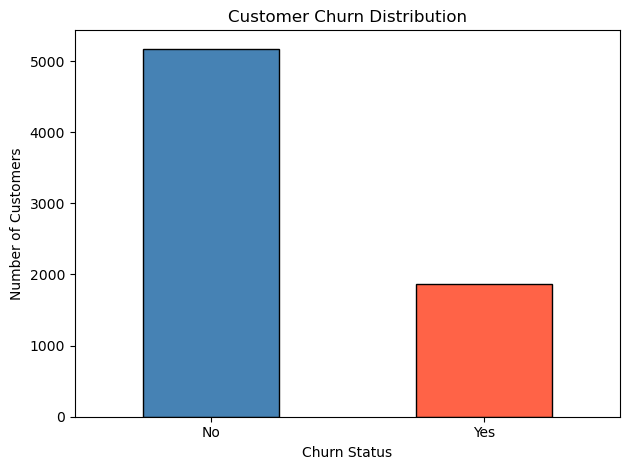

In [10]:
churn_counts = df["Churn"].value_counts()

churn_counts.plot(
    kind="bar",
    color=["steelblue", "tomato"],
    edgecolor="black"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"])

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [12]:
contract_churn_percent = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn_percent.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


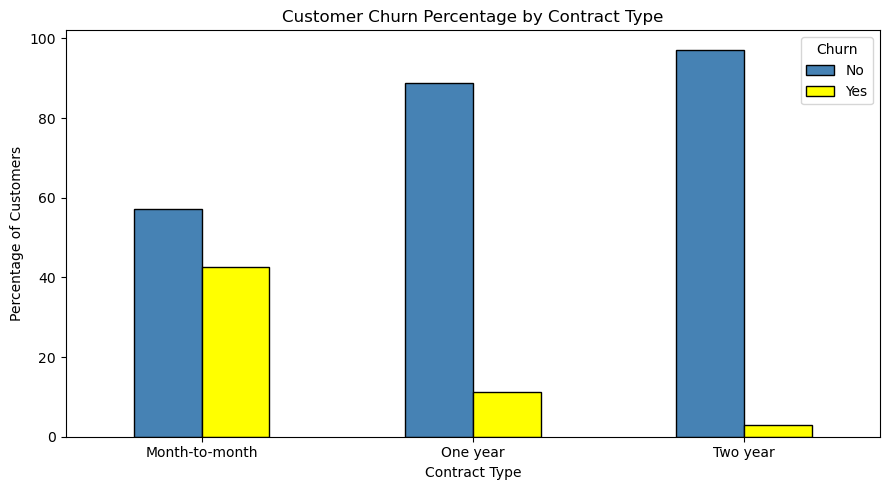

In [13]:
contract_churn_percent.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "yellow"],
    edgecolor="black"
)

plt.title("Customer Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [14]:
df.groupby("Churn")["tenure"].mean().round(2)

Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

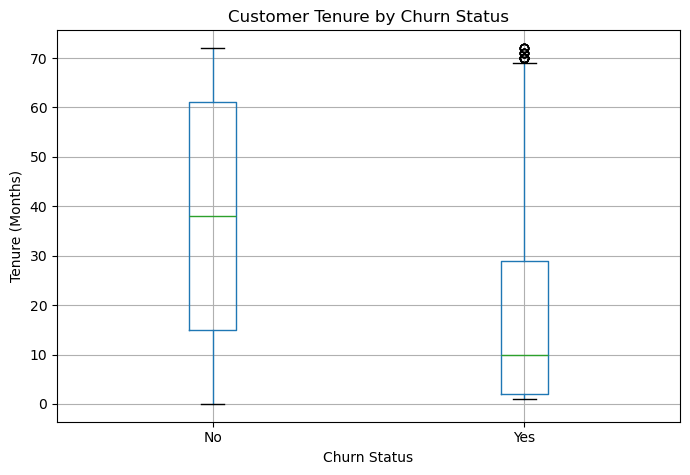

In [15]:
df.boxplot(
    column="tenure",
    by="Churn",
    figsize=(7, 5)
)

plt.title("Customer Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

In [16]:
df.groupby("Churn")["MonthlyCharges"].mean().round(2)

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

In [17]:
print("TotalCharges data type:")
print(df["TotalCharges"].dtype)

print("Blank TotalCharges values:")
print((df["TotalCharges"].astype(str).str.strip() == "").sum())

TotalCharges data type:
object
Blank TotalCharges values:
11


In [18]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing values after cleaning:")
print(df["TotalCharges"].isnull().sum())

print("New data type:")
print(df["TotalCharges"].dtype)

Missing values after cleaning:
11
New data type:
float64


In [19]:
df = df.dropna(subset=["TotalCharges"]).copy()

print("Dataset shape after cleaning:", df.shape)
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Dataset shape after cleaning: (7032, 21)
Missing TotalCharges: 0


In [20]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   tenure          7032 non-null   int64  
 1   MonthlyCharges  7032 non-null   float64
 2   TotalCharges    7032 non-null   float64
dtypes: float64(2), int64(1)
memory usage: 219.8 KB


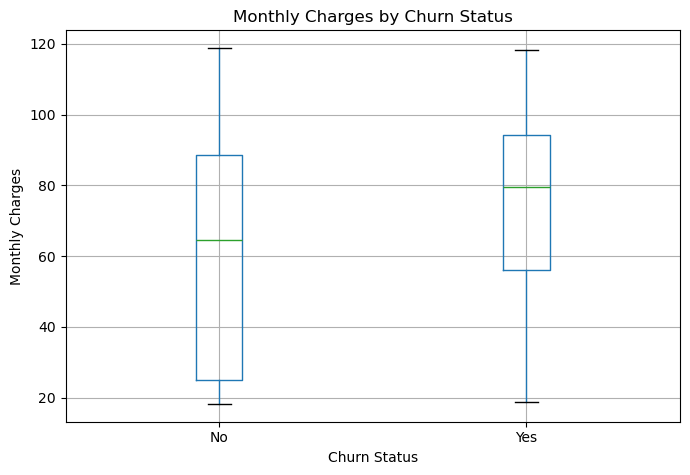

In [32]:
df.boxplot(
    column="MonthlyCharges",
    by="Churn",
    figsize=(7, 5)
)

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [35]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.27,16.73
Credit card (automatic),84.75,15.25
Electronic check,54.71,45.29
Mailed check,80.80,19.20


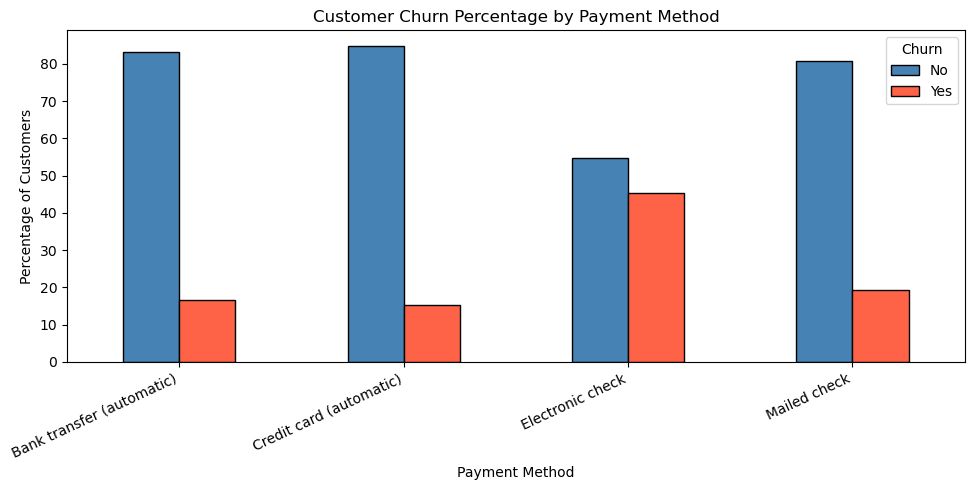

In [36]:
payment_churn.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "tomato"],
    edgecolor="black"
)

plt.title("Customer Churn Percentage by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [37]:
df_model = df.drop("customerID", axis=1).copy()

print("Original dataset shape:", df.shape)
print("Dataset shape after removing ID:", df_model.shape)

Original dataset shape: (7032, 21)
Dataset shape after removing ID: (7032, 20)


In [38]:
X = df_model.drop("Churn", axis=1)
y = df_model["Churn"].map({"No": 0, "Yes": 1})

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Input features shape: (7032, 19)
Target shape: (7032,)

Target values:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [39]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Shape after encoding:", X.shape)
X.head()

Shape after encoding: (7032, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5625, 30)
Testing features: (1407, 30)
Training target: (5625,)
Testing target: (1407,)


In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = LogisticRegression(max_iter=5000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred) * 100)

print(classification_report(y_test, y_pred))

Accuracy: 80.45486851457001
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.58      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf) * 100)

Random Forest Accuracy: 78.96233120113718


In [44]:
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred) * 100)

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf) * 100)

Logistic Regression Accuracy: 80.45486851457001
Random Forest Accuracy: 78.96233120113718


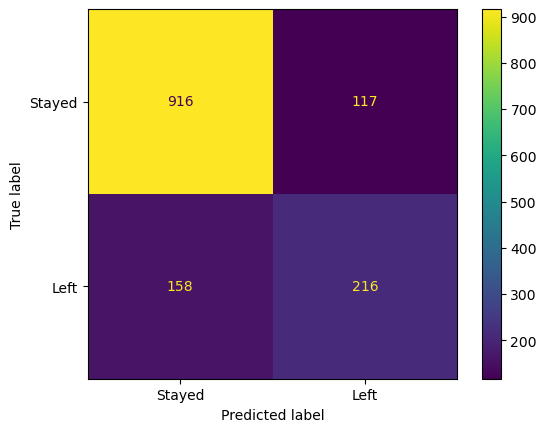

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Stayed", "Left"]
)
plt.show()

In [46]:
importance = rf_model.feature_importances_

features = X.columns

print(sorted(zip(features, importance),
             key=lambda x: x[1], reverse=True)[:10])

[('TotalCharges', np.float64(0.19143548769418997)), ('tenure', np.float64(0.17102034135171149)), ('MonthlyCharges', np.float64(0.16840004321240998)), ('InternetService_Fiber optic', np.float64(0.039480962089756065)), ('PaymentMethod_Electronic check', np.float64(0.037416133088428415)), ('Contract_Two year', np.float64(0.030529146942460332)), ('gender_Male', np.float64(0.02933204954212285)), ('OnlineSecurity_Yes', np.float64(0.02815701615922195)), ('PaperlessBilling_Yes', np.float64(0.025535655150434294)), ('TechSupport_Yes', np.float64(0.024113755927092504))]


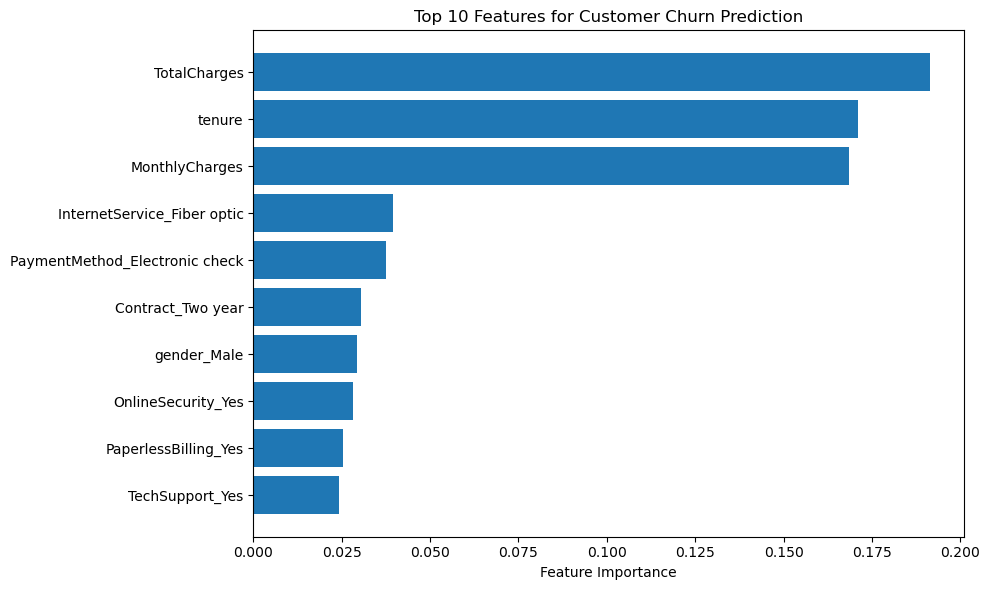

In [47]:
import matplotlib.pyplot as plt

features = [
    'TotalCharges', 'tenure', 'MonthlyCharges',
    'InternetService_Fiber optic',
    'PaymentMethod_Electronic check',
    'Contract_Two year', 'gender_Male',
    'OnlineSecurity_Yes', 'PaperlessBilling_Yes',
    'TechSupport_Yes'
]

scores = [
    0.19145, 0.17102, 0.16840, 0.03949, 0.03742,
    0.03053, 0.02933, 0.02816, 0.02536, 0.02411
]

plt.figure(figsize=(10, 6))
plt.barh(features[::-1], scores[::-1])
plt.xlabel("Feature Importance")
plt.title("Top 10 Features for Customer Churn Prediction")
plt.tight_layout()
plt.show()